In [58]:
import h5py
import pylab as plt
import numpy as np
from matplotlib.dates import num2date
from datetime import datetime
import pytz

# Load Samples Data

In [59]:
hdf_samples = h5py.File('../data/validation/unsignedflux_samples.h5')
print(hdf_samples.keys())
#lat_extent_samples = hdf_samples['lat_extent'][:].squeeze()
unsigned_flux_samples = hdf_samples['unsigned_flux'][:].squeeze()
times_d2n = hdf_samples['times_d2n'][:]
hdf_samples.close()

<KeysViewHDF5 ['contexts', 'rs', 'times_d2n', 'unsigned_flux']>


In [60]:
unsigned_flux_samples.shape

(835, 4)

In [61]:
times_samples = np.array(num2date(times_d2n))

In [62]:
unsigned_flux_samples

array([[163257.99683374,   5669.60373608,   2835.29261385,
          1933.36120829],
       [164177.77393345,   7052.9241625 ,   3439.52820623,
          2346.11368976],
       [179789.23068749,   7062.08469461,   3783.69136587,
          2721.76177909],
       ...,
       [208310.95987249,  11111.13479525,   5837.78129998,
          3987.62578024],
       [212299.75981128,   9933.77069993,   4602.59555097,
          2990.588931  ],
       [194971.80526569,   8004.91852866,   3351.38985165,
          2119.67759811]], shape=(835, 4))

# Load Training Data

In [71]:
hdf_testdata = h5py.File('../data/validation/unsignedflux_testdata.h5')
unsigned_flux_testdata = hdf_testdata['unsigned_flux'][:].squeeze()
hdf_testdata.close()

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '../data/validation/unsignedflux_testdata.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [64]:
unsigned_flux_testdata.shape

(835, 4)

In [65]:
unsigned_flux_testdata

array([[8838.75045032,  125.16969916,   73.93054553,   56.6705114 ],
       [7006.58860882,  112.67452602,   68.19751902,   53.62942578],
       [9832.99690597,  128.5315152 ,   69.45565018,   50.9835439 ],
       ...,
       [6644.9821804 ,  122.05837973,   80.53725849,   64.79074303],
       [6644.9821804 ,  122.05837973,   80.53725849,   64.79074303],
       [6644.9821804 ,  122.05837973,   80.53725849,   64.79074303]],
      shape=(835, 4))

# Plot Experiment

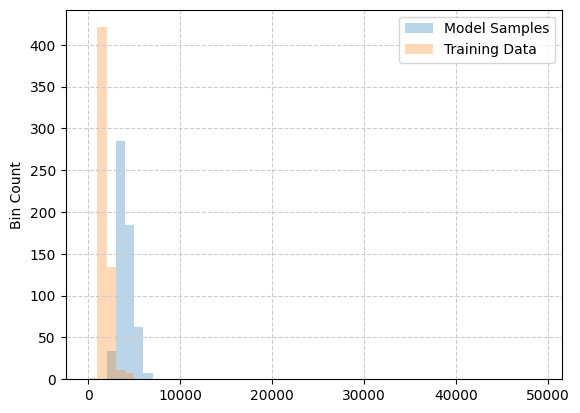

In [85]:
#bins = np.arange(0, 50000, 1000)

bins = np.arange(0, 500_000, 10000) / 10

cutoff = datetime(2021, 1, 1).replace(tzinfo=pytz.utc)
mask = times_samples < cutoff

plt.hist(unsigned_flux_samples[mask, 2], label='Model Samples', bins=bins, alpha=0.3)
plt.hist(unsigned_flux_testdata[mask, 2] * (np.pi * 4 * np.sqrt(2)), bins=bins,  label='Training Data', alpha=0.3)

plt.legend()
plt.ylabel('Bin Count')
#plt.xlabel(r'Latitudinal Extent of Current Sheet at 2.5 $R_\odot$ (deg)')
#plt.title('Histograms of Latitudinal Extent of Current Sheet at 2.5 $R_\odot$')
#plt.xlim(0, 180)
plt.grid(linestyle='dashed', color='#ccc')
#plt.savefig('../plots/paper/csextent.png', dpi=300)

In [80]:
for i in range(4):
    print(np.mean(unsigned_flux_testdata[mask, i])  /  np.mean(unsigned_flux_samples[mask, i]) )

0.06702582543204377
0.025983409025013872
0.024915143964332892
0.024693298112723378


In [68]:
 1/ (np.pi * 4 * np.sqrt(2))

np.float64(0.05626976975981913)

In [69]:
print('Samples')
print('---------')
print('Mean', np.mean(unsigned_flux_samples[times_samples < cutoff]))
print('STD', np.std(unsigned_flux_samples[times_samples < cutoff]))
print()
print('Training Data')
print('---------')
print('Mean', np.mean(unsigned_flux_testdata[times_samples < cutoff]))
print('STD', np.std(unsigned_flux_testdata[times_samples < cutoff]))
print()

Samples
---------
Mean 54631.609377487
STD 92191.8014935117

Training Data
---------
Mean 3505.5181280551915
STD 6726.173482722593

